# Clasificación de `type` de dinosaurio con modelos ensemble
**Objetivo:** predecir `type` (6 clases) a partir de la longitud, la edad y la ubicación de un dinosaurio.

| Requisito del README | Dónde se cubre |
|---|---|
| Modelo ensemble (Random Forest, Gradient Boosting) | secciones 4 y 5 |
| Validación cruzada | secciones 3, 4 y 5 (`RepeatedStratifiedKFold`) |
| Optimización de hiperparámetros | sección 4 (`RandomizedSearchCV`) |
| Overfitting < 5 % | sección 4 (restricción en la elección del modelo) |
| Informe: accuracy, precision, recall, F1, ROC, matriz de confusión | sección 6 |
| Explicación: feature importance y análisis de errores | secciones 7 y 8 |

**Decisiones heredadas del EDA:** se excluyen `class`, `family`, `diet` (fugas), `name` y `occurrence_no` (identificadores),
`region` (demasiadas categorías) y `duracion` (efecto despreciable).

**Definición de sobreajuste usada:** F1 macro en train − F1 macro en validación (puntos absolutos). Límite: 0,05.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform, randint
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             confusion_matrix, f1_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (RandomizedSearchCV, RepeatedStratifiedKFold, StratifiedGroupKFold,
                                     StratifiedKFold, cross_validate, train_test_split)
from sklearn.preprocessing import label_binarize

sns.set_theme(style="whitegrid")

RUTA = "../data/dinosaurs.xlsx"      # <- ajusta la ruta
HOJA = "dinosaurs"           # "dinosaurs" (4951 filas) o "Tabla1" (2793 filas completas)
TARGET = "type"
SEMILLA = 42
N_ITER = 60                  # candidatos probados por modelo en la búsqueda de hiperparámetros
MAX_GAP = 0.05               # límite de sobreajuste (diferencia absoluta de F1 macro)

## 1. Carga y limpieza (a nivel de hallazgo fósil)

In [2]:
df = pd.read_excel(RUTA, sheet_name=HOJA)
print("Filas cargadas:", len(df))

df = df.dropna(subset=[TARGET, "length_m"])           # solo filas etiquetadas y con longitud
fuera = (df["lng"].abs() > 180) | (df["lat"].abs() > 90)   # coordenadas imposibles (p. ej. lng = 565)
print("Filas con coordenadas imposibles descartadas:", int(fuera.sum()))
df = df[~fuera].reset_index(drop=True)
df["edad_media"] = (df["max_ma"] + df["min_ma"]) / 2
print(f"Filas usadas: {len(df)} | taxones distintos: {df['name'].nunique()}")

Filas cargadas: 4951
Filas con coordenadas imposibles descartadas: 0
Filas usadas: 3568 | taxones distintos: 288


## 2. Unidad de análisis: **una fila por taxón**
En el EDA vimos que cada `name` tiene siempre el mismo `type` y la misma `length_m`. Las 3567 filas son
hallazgos repetidos de solo 288 dinosaurios, y eso rompe la validación:
si un mismo dinosaurio cae en train y en validación, el modelo lo "reconoce" y las métricas salen infladas.

Por eso resumimos cada taxón en una fila: longitud (constante), edad media de sus hallazgos y latitud/longitud medianas.
Con filas independientes la validación cruzada estándar es legítima. Comparamos los enfoques con un Random Forest sin ajustar:

In [3]:
FEATURES = ["length_m", "edad_media", "lat", "lng"]

taxones = (df.groupby("name")
             .agg(type=(TARGET, "first"), length_m=("length_m", "first"), edad_media=("edad_media", "mean"),
                  lat=("lat", "median"), lng=("lng", "median"), n_hallazgos=(TARGET, "size"))
             .reset_index())
assert (df.groupby("name")[TARGET].nunique() == 1).all() and (df.groupby("name")["length_m"].nunique() == 1).all()
print("Taxones:", len(taxones))
print(taxones[TARGET].value_counts().to_string())

def evalua(modelo, X, y, cv, grupos=None):
    r = cross_validate(modelo, X, y, cv=cv, groups=grupos, scoring="f1_macro", return_train_score=True, n_jobs=-1)
    tr, va = r["train_score"].mean(), r["test_score"].mean()
    return {"F1 train": round(tr, 3), "F1 validación": round(va, 3), "sobreajuste": round(tr - va, 3)}

rf0 = RandomForestClassifier(n_estimators=200, random_state=SEMILLA)
rf_corto = RandomForestClassifier(n_estimators=200, max_depth=2, min_samples_leaf=100, random_state=SEMILLA)
cv_filas_grupo = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
cv_taxon = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEMILLA)

comparacion = pd.DataFrame({
    "Baseline (clase mayoritaria), taxones": evalua(DummyClassifier(strategy="most_frequent"), taxones[FEATURES], taxones[TARGET], cv_taxon),
    "A. Filas + validación AL AZAR (con fuga)": evalua(rf0, df[FEATURES], df[TARGET], StratifiedKFold(5, shuffle=True, random_state=SEMILLA)),
    "B. Filas + validación por taxón": evalua(rf0, df[FEATURES], df[TARGET], cv_filas_grupo, df["name"]),
    "C. Filas + por taxón + modelo muy restringido": evalua(rf_corto, df[FEATURES], df[TARGET], cv_filas_grupo, df["name"]),
    "D. Una fila por taxón (enfoque elegido, RF sin ajustar)": evalua(rf0, taxones[FEATURES], taxones[TARGET], cv_taxon),
}).T
comparacion

Taxones: 288
type
sauropod            68
large theropod      59
small theropod      56
ornithopod          54
armored dinosaur    28
ceratopsian         23


,F1 train,F1 validación,sobreajuste
"Baseline (clase mayoritaria), taxones",0.064,0.064,0.000
A. Filas + validación AL AZAR (con fuga),0.990,0.903,0.087
B. Filas + validación por taxón,0.990,0.453,0.538
C. Filas + por taxón + modelo muy restringido,0.373,0.342,0.031
"D. Una fila por taxón (enfoque elegido, RF sin ajustar)",1.000,0.401,0.599


- **A** parece excelente, pero es una ilusión: el modelo ve en train a los mismos dinosaurios que evalúa.
- **B** es la medida honesta a nivel de fila, pero el sobreajuste es enorme: el modelo memoriza los taxones de train.
- **C** muestra que, restringiendo mucho el modelo, el sobreajuste baja hasta rondar el límite, a costa de capacidad
  (compara su F1 con el de B). Es decir, cumplir el 5 % obliga a un modelo muy simple con cualquiera de los dos enfoques.
- **D** (una fila por taxón, aquí con un bosque sin ajustar) mide el rendimiento sobre dinosaurios nuevos igual que B,
  pero con filas independientes: la validación estándar es legítima y los taxones con muchos hallazgos no pesan más que el resto.

**Contrapartida:** solo hay 288 filas. Las métricas serán menos estables y la ubicación se resume en una mediana por taxón.

## 3. Separación train / test
El test (25 % de los taxones, estratificado) queda apartado hasta el informe final.

In [4]:
X, y = taxones[FEATURES], taxones[TARGET]
X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, taxones.index, test_size=0.25, stratify=y, random_state=SEMILLA)
print(f"Train: {len(X_train)} taxones | Test: {len(X_test)} taxones")
print(pd.DataFrame({"train": y_train.value_counts(), "test": y_test.value_counts()}))

# Validación cruzada para todo el ajuste: 5 folds estratificados × 3 repeticiones
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEMILLA)

Train: 216 taxones | Test: 72 taxones
                  train  test
type                         
sauropod             51    17
large theropod       44    15
small theropod       42    14
ornithopod           41    13
armored dinosaur     21     7
ceratopsian          17     6


## 4. Optimización de hiperparámetros (Random Forest y Gradient Boosting)
`RandomizedSearchCV` con validación cruzada repetida. Se guarda también la puntuación de **train** de cada candidato
para medir su sobreajuste.

In [5]:
espacio_rf = {
    "n_estimators": randint(100, 400),
    "max_depth": [2, 3, 4, 5, 6, None],
    "min_samples_leaf": [1, 2, 5, 10, 15, 20, 30, 40],
    "max_features": ["sqrt", 0.5, 1.0],
    "class_weight": [None, "balanced"],
    "criterion": ["gini", "entropy"],
}
espacio_gb = {
    "learning_rate": loguniform(0.01, 0.3),
    "max_iter": randint(20, 200),
    "max_depth": [1, 2, 3, 4],
    "min_samples_leaf": [5, 10, 20, 30, 40],
    "max_leaf_nodes": [3, 4, 6, 8, 15],
    "l2_regularization": loguniform(0.1, 100),
}

def busca(modelo, espacio):
    b = RandomizedSearchCV(modelo, espacio, n_iter=N_ITER, scoring="f1_macro", cv=cv, return_train_score=True,
                           refit=False, random_state=SEMILLA, n_jobs=-1)
    b.fit(X_train, y_train)
    r = pd.DataFrame(b.cv_results_)
    r["sobreajuste"] = r["mean_train_score"] - r["mean_test_score"]
    return r

plantillas = {"Random Forest": RandomForestClassifier(random_state=SEMILLA),
              "Gradient Boosting": HistGradientBoostingClassifier(random_state=SEMILLA)}
resultados = {"Random Forest": busca(plantillas["Random Forest"], espacio_rf),
              "Gradient Boosting": busca(plantillas["Gradient Boosting"], espacio_gb)}
print({n: len(r) for n, r in resultados.items()}, "candidatos evaluados")

{'Random Forest': 60, 'Gradient Boosting': 60} candidatos evaluados


### Elección del modelo con la restricción de sobreajuste
Entre los candidatos con `sobreajuste ≤ 0,05` se elige el de mayor F1 de validación. Se guarda también el mejor
**sin** restricción para ver cuánto cuesta cumplir el límite.

,modelo,versión,F1 val.,F1 train,sobreajuste,cumple <5 %
0,Random Forest,mejor SIN restricción,0.450,0.857,0.407,False
1,Random Forest,mejor CON restricción,0.336,0.385,0.049,True
2,Gradient Boosting,mejor SIN restricción,0.419,1.000,0.581,False
3,Gradient Boosting,mejor CON restricción,0.330,0.378,0.048,True


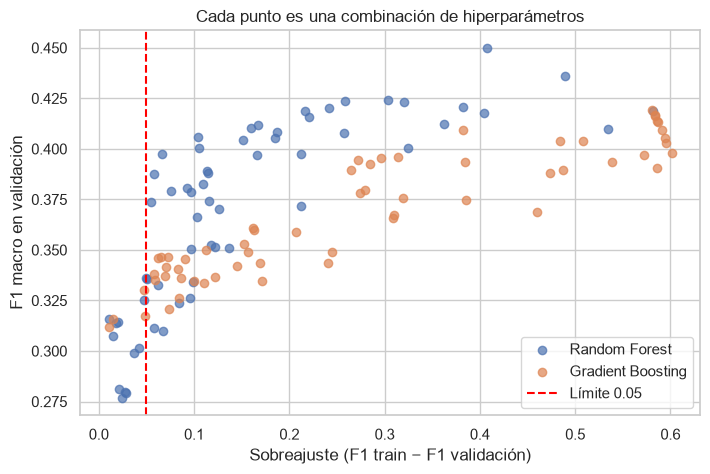

In [6]:
def elige(res, max_gap=MAX_GAP):
    validos = res[res["sobreajuste"] <= max_gap]
    cumple = not validos.empty
    fila = validos.loc[validos["mean_test_score"].idxmax()] if cumple else res.loc[res["sobreajuste"].idxmin()]
    return fila, cumple

resumen, elegidos = [], {}
for nombre, res in resultados.items():
    libre = res.loc[res["mean_test_score"].idxmax()]
    fila, cumple = elige(res)
    elegidos[nombre] = (fila, cumple)
    for version, f, ok in [("mejor SIN restricción", libre, libre["sobreajuste"] <= MAX_GAP),
                           ("mejor CON restricción", fila, cumple)]:
        resumen.append({"modelo": nombre, "versión": version, "F1 val.": f["mean_test_score"],
                        "F1 train": f["mean_train_score"], "sobreajuste": f["sobreajuste"], "cumple <5 %": ok})
display(pd.DataFrame(resumen).round(3))

plt.figure(figsize=(8, 5))
for nombre, res in resultados.items():
    plt.scatter(res["sobreajuste"], res["mean_test_score"], label=nombre, alpha=0.7)
plt.axvline(MAX_GAP, color="red", ls="--", label=f"Límite {MAX_GAP:.2f}")
plt.xlabel("Sobreajuste (F1 train − F1 validación)")
plt.ylabel("F1 macro en validación")
plt.title("Cada punto es una combinación de hiperparámetros")
plt.legend()
plt.show()

In [7]:
cumplen = {n: f for n, (f, c) in elegidos.items() if c}
candidatos = cumplen if cumplen else {n: f for n, (f, _) in elegidos.items()}
nombre_final = max(candidatos, key=lambda n: candidatos[n]["mean_test_score"])
params_finales = candidatos[nombre_final]["params"]
print("Modelo elegido:", nombre_final)
print("Hiperparámetros:", params_finales)
if not cumplen:
    print("AVISO: ningún candidato cumple el límite; se ha elegido el de menor sobreajuste.")

modelo = clone(plantillas[nombre_final]).set_params(**params_finales).fit(X_train, y_train)

Modelo elegido: Random Forest
Hiperparámetros: {'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 2, 'max_features': 1.0, 'min_samples_leaf': 20, 'n_estimators': 358}


## 5. Validación cruzada del modelo final (estabilidad por fold)

In [8]:
r = cross_validate(clone(modelo), X_train, y_train, cv=cv, scoring=["f1_macro", "accuracy"],
                   return_train_score=True, n_jobs=-1)
por_fold = pd.DataFrame({"F1 train": r["train_f1_macro"], "F1 validación": r["test_f1_macro"],
                         "accuracy validación": r["test_accuracy"]})
por_fold["sobreajuste"] = por_fold["F1 train"] - por_fold["F1 validación"]
print(f"{len(por_fold)} folds (5 × 3 repeticiones). Resumen:")
por_fold.agg(["mean", "std", "min", "max"]).round(3)

15 folds (5 × 3 repeticiones). Resumen:


,F1 train,F1 validación,accuracy validación,sobreajuste
mean,0.385,0.336,0.470,0.049
std,0.038,0.056,0.054,0.047
min,0.342,0.264,0.395,-0.016
max,0.485,0.495,0.591,0.130


## 6. Informe de rendimiento en el conjunto de test
Taxones que el modelo no ha visto ni en el entrenamiento ni en la búsqueda de hiperparámetros.
**Ojo:** el test tiene pocos taxones, así que cada acierto o fallo mueve bastante las métricas.

In [9]:
pred = modelo.predict(X_test)
proba = modelo.predict_proba(X_test)
clases = list(modelo.classes_)

f1_train = f1_score(y_train, modelo.predict(X_train), average="macro")
f1_test = f1_score(y_test, pred, average="macro")
auc_macro = roc_auc_score(y_test, proba, multi_class="ovr", average="macro", labels=clases)
f1_base = f1_score(y_test, DummyClassifier(strategy="most_frequent").fit(X_train, y_train).predict(X_test), average="macro")

print(f"Accuracy:        {accuracy_score(y_test, pred):.3f}")
print(f"F1 macro:        {f1_test:.3f}   (baseline: {f1_base:.3f})")
print(f"F1 macro train:  {f1_train:.3f}   → sobreajuste train-test: {f1_train - f1_test:.3f}")
print(f"AUC macro (OvR): {auc_macro:.3f}")
print(f"Clases distintas predichas: {len(set(pred))} de {len(clases)}")
print()
pd.DataFrame(classification_report(y_test, pred, output_dict=True, zero_division=0)).T.round(3)

Accuracy:        0.472
F1 macro:        0.347   (baseline: 0.064)
F1 macro train:  0.356   → sobreajuste train-test: 0.010
AUC macro (OvR): 0.772
Clases distintas predichas: 4 de 6



,precision,recall,f1-score,support
armored dinosaur,0.333,0.286,0.308,7.000
ceratopsian,0.000,0.000,0.000,6.000
large theropod,0.300,0.600,0.400,15.000
ornithopod,0.000,0.000,0.000,13.000
sauropod,0.688,0.647,0.667,17.000
small theropod,0.600,0.857,0.706,14.000
accuracy,0.472,0.472,0.472,0.472
macro avg,0.320,0.398,0.347,72.000
weighted avg,0.374,0.472,0.408,72.000


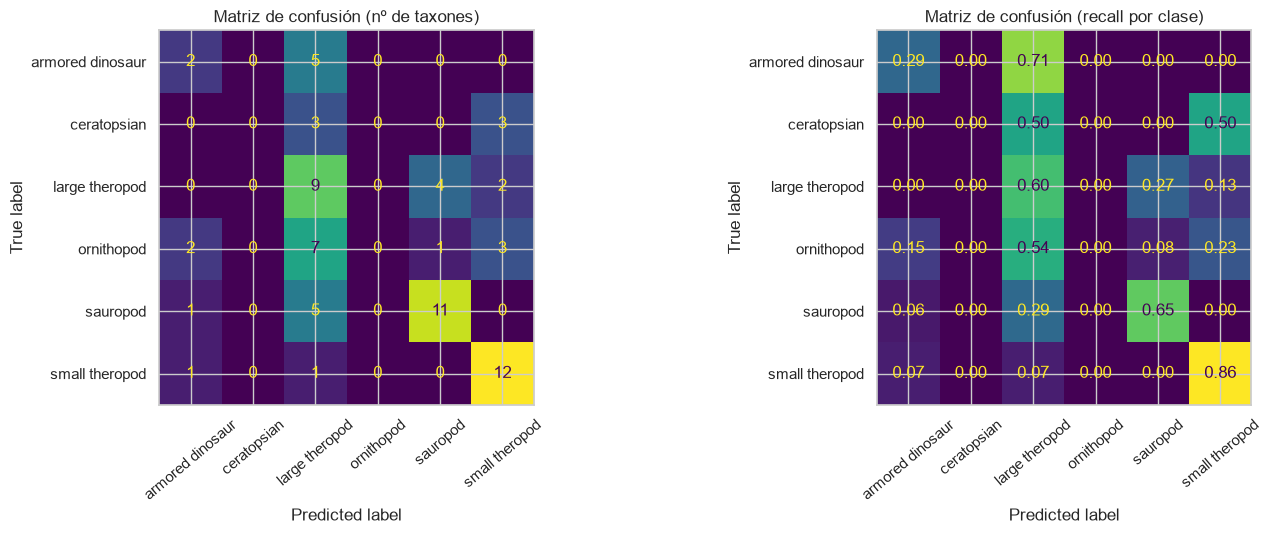

In [10]:
fig, ejes = plt.subplots(1, 2, figsize=(15, 5.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=clases, ax=ejes[0], xticks_rotation=40, colorbar=False)
ejes[0].set_title("Matriz de confusión (nº de taxones)")
ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=clases, normalize="true", values_format=".2f",
                                        ax=ejes[1], xticks_rotation=40, colorbar=False)
ejes[1].set_title("Matriz de confusión (recall por clase)")
plt.tight_layout()
plt.show()

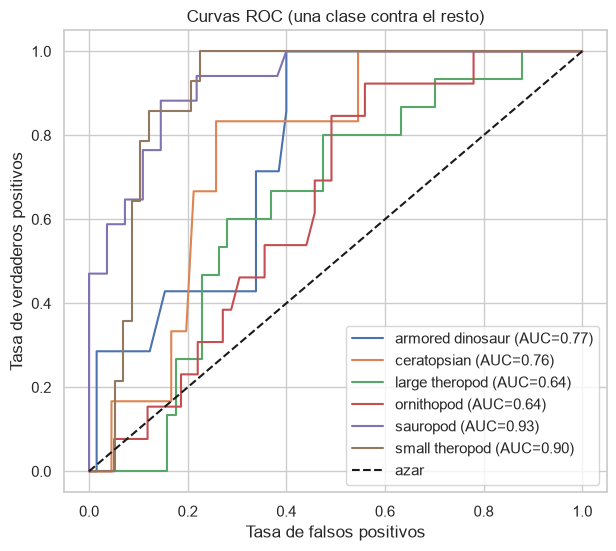

In [11]:
y_bin = label_binarize(y_test, classes=clases)
plt.figure(figsize=(7, 6))
for i, c in enumerate(clases):
    fpr, tpr, _ = roc_curve(y_bin[:, i], proba[:, i])
    plt.plot(fpr, tpr, label=f"{c} (AUC={roc_auc_score(y_bin[:, i], proba[:, i]):.2f})")
plt.plot([0, 1], [0, 1], "k--", label="azar")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("Curvas ROC (una clase contra el resto)")
plt.legend(loc="lower right")
plt.show()

## 7. ¿Qué variables usa el modelo? (feature importance)
Importancia por permutación en test: cuánto empeora el F1 macro al desordenar cada variable.

  variable  importancia  desv
  length_m        0.211 0.036
edad_media        0.000 0.000
       lat        0.000 0.000
       lng        0.000 0.000


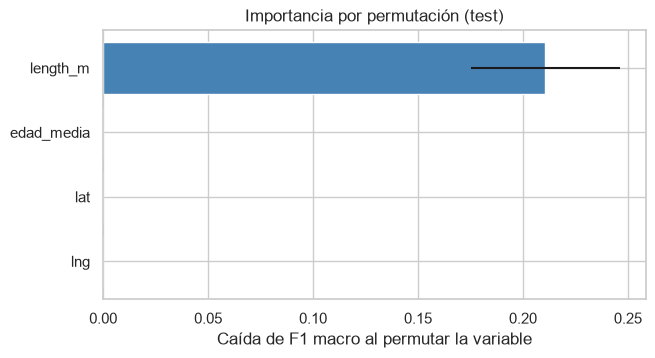


Importancia interna del modelo (impureza):
length_m      0.897
edad_media    0.051
lng           0.041
lat           0.011


In [12]:
perm = permutation_importance(modelo, X_test, y_test, scoring="f1_macro", n_repeats=50, random_state=SEMILLA, n_jobs=-1)
imp = pd.DataFrame({"variable": FEATURES, "importancia": perm.importances_mean, "desv": perm.importances_std}) \
        .sort_values("importancia", ascending=False)
print(imp.round(3).to_string(index=False))

plt.figure(figsize=(7, 3.5))
plt.barh(imp["variable"], imp["importancia"], xerr=imp["desv"], color="steelblue")
plt.gca().invert_yaxis()
plt.xlabel("Caída de F1 macro al permutar la variable")
plt.title("Importancia por permutación (test)")
plt.show()

if hasattr(modelo, "feature_importances_"):
    print("\nImportancia interna del modelo (impureza):")
    print(pd.Series(modelo.feature_importances_, index=FEATURES).sort_values(ascending=False).round(3).to_string())

## 8. Análisis de errores

In [13]:
res = taxones.loc[id_test, ["name", "type"] + FEATURES + ["n_hallazgos"]].copy()
res["pred"] = pred
res["acierto"] = res["type"] == res["pred"]

# 8.1 Confusiones más frecuentes
cm = pd.DataFrame(confusion_matrix(y_test, pred, labels=clases), index=clases, columns=clases)
err = cm.stack().rename("n").reset_index()
err.columns = ["real", "predicha", "n"]
err = err[(err["real"] != err["predicha"]) & (err["n"] > 0)].sort_values("n", ascending=False).head(8)
print("Confusiones más frecuentes (nº de taxones):")
print(err.to_string(index=False))

Confusiones más frecuentes (nº de taxones):
            real       predicha  n
      ornithopod large theropod  7
        sauropod large theropod  5
armored dinosaur large theropod  5
  large theropod       sauropod  4
     ceratopsian large theropod  3
      ornithopod small theropod  3
     ceratopsian small theropod  3
  large theropod small theropod  2


In [14]:
# 8.2 Taxones mal clasificados
print(f"Taxones en test: {len(res)} | bien: {int(res['acierto'].sum())} | mal: {int((~res['acierto']).sum())}\n")
print("Fallos (ordenados por nº de hallazgos):")
res.loc[~res["acierto"], ["name", "type", "pred", "length_m", "edad_media", "lat", "lng", "n_hallazgos"]] \
   .sort_values("n_hallazgos", ascending=False).round(1).head(15)

Taxones en test: 72 | bien: 34 | mal: 38

Fallos (ordenados por nº de hallazgos):


,name,type,pred,length_m,edad_media,lat,lng,n_hallazgos
13,Allosaurus,large theropod,sauropod,12.0,150.6,40.4,-106.1,103
87,Edmontosaurus,ornithopod,sauropod,13.0,70.0,45.6,-105.2,66
162,Massospondylus,sauropod,armored dinosaur,4.0,194.9,-29.0,27.8,40
219,Rhabdodon,ornithopod,armored dinosaur,4.0,73.4,43.3,2.9,37
214,Protoceratops,ceratopsian,small theropod,1.8,79.0,44.1,103.3,33
205,Plateosaurus,sauropod,large theropod,7.0,213.0,48.7,8.6,31
192,Pachycephalosaurus,ornithopod,large theropod,8.0,69.4,45.8,-105.1,30
228,Sauropelta,armored dinosaur,large theropod,6.5,108.3,45.4,-108.2,29
50,Camptosaurus,ornithopod,large theropod,5.0,152.0,40.4,-106.9,27
84,Dryosaurus,ornithopod,armored dinosaur,4.0,152.2,41.9,-106.1,23


Longitud (m) por clase real:
                  min  25%   50%   75%   max
type                                        
armored dinosaur  1.2  4.0   5.0   6.7  10.0
ceratopsian       0.5  1.4   5.0   6.0   9.0
large theropod    2.0  5.2   7.0   9.5  18.0
ornithopod        0.8  2.6   5.5   8.8  15.0
sauropod          2.0  9.0  15.0  21.0  35.0
small theropod    0.4  1.0   1.8   2.4   5.0


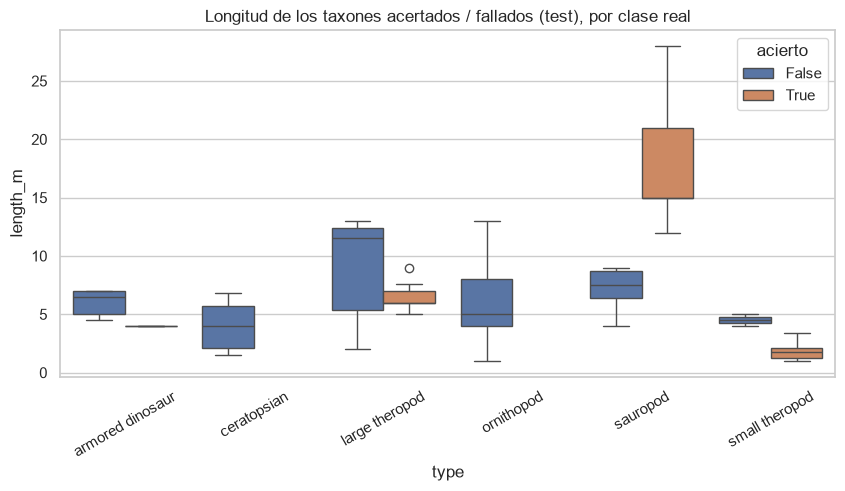

In [15]:
# 8.3 ¿En qué rango de longitud se falla? Solapamiento de tamaños entre clases (todos los taxones)
print("Longitud (m) por clase real:")
print(taxones.groupby(TARGET)["length_m"].describe()[["min", "25%", "50%", "75%", "max"]].round(1))

plt.figure(figsize=(10, 4.5))
sns.boxplot(data=res, x="type", y="length_m", hue="acierto", order=clases)
plt.xticks(rotation=30)
plt.title("Longitud de los taxones acertados / fallados (test), por clase real")
plt.show()

In [16]:
# 8.4 ¿Fallan más los taxones con pocos hallazgos? (su edad y ubicación medianas serían menos fiables)
print(f"Nº medio de hallazgos por taxón: aciertos = {res.loc[res['acierto'], 'n_hallazgos'].mean():.1f} | fallos = {res.loc[~res['acierto'], 'n_hallazgos'].mean():.1f}")

# 8.5 Clases nunca predichas (recall = 0)
nunca = [c for c in clases if c not in set(pred)]
print("Clases que el modelo no predice nunca en test:", nunca if nunca else "ninguna")

Nº medio de hallazgos por taxón: aciertos = 16.9 | fallos = 15.5
Clases que el modelo no predice nunca en test: ['ceratopsian', 'ornithopod']


## 9. Resumen automático y guardado del modelo

In [17]:
fila_sel = candidatos[nombre_final]
mejor_libre = max(r_["mean_test_score"].max() for r_ in resultados.values())
print(f"Modelo: {nombre_final} | {params_finales}")
print(f"Validación cruzada (train): F1 macro {fila_sel['mean_test_score']:.3f} | sobreajuste {fila_sel['sobreajuste']:.3f} "
      f"→ {'CUMPLE' if fila_sel['sobreajuste'] <= MAX_GAP else 'NO cumple'} el límite de {MAX_GAP}")
print(f"Test: accuracy {accuracy_score(y_test, pred):.3f} | F1 macro {f1_test:.3f} (baseline {f1_base:.3f}) | AUC macro {auc_macro:.3f}")
print(f"Sobreajuste train-test: {f1_train - f1_test:.3f}")
print(f"Mejor F1 de validación SIN restricción de sobreajuste: {mejor_libre:.3f}  (coste de cumplir el límite: {mejor_libre - fila_sel['mean_test_score']:.3f})")

joblib.dump({"modelo": modelo, "features": FEATURES, "clases": clases}, "../models/modelo_type_dinosaurios.joblib")
print("\nModelo guardado en modelo_type_dinosaurios.joblib (listo para la app de Streamlit/Gradio).")

Modelo: Random Forest | {'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 2, 'max_features': 1.0, 'min_samples_leaf': 20, 'n_estimators': 358}
Validación cruzada (train): F1 macro 0.336 | sobreajuste 0.049 → CUMPLE el límite de 0.05
Test: accuracy 0.472 | F1 macro 0.347 (baseline 0.064) | AUC macro 0.772
Sobreajuste train-test: 0.010
Mejor F1 de validación SIN restricción de sobreajuste: 0.450  (coste de cumplir el límite: 0.114)

Modelo guardado en modelo_type_dinosaurios.joblib (listo para la app de Streamlit/Gradio).


## 10. Conclusiones

### Resumen

| Aspecto | Resultado |
|---|---|
| Unidad de análisis | Una fila por taxón (288 taxones) |
| Modelo elegido | Random Forest (`max_depth=2`, `min_samples_leaf=20`, `class_weight="balanced"`, 358 árboles) |
| F1 macro en validación cruzada | 0,336 |
| F1 macro en test | 0,347 (baseline: 0,064) |
| Sobreajuste en validación cruzada | 0,049 (cumple el límite de 0,05) |
| Limitación principal | El modelo no predice nunca ceratopsio ni ornitópodo |

### 1. Enfoque: una fila por taxón

Cada taxón tiene un único `type` y una única `length_m`, de modo que las 3567 filas son hallazgos repetidos de 288 dinosaurios. Con validación al azar, un mismo taxón aparece a la vez en train y en test, y el F1 resulta inflado (0,905 frente a 0,438 al validar por taxón). Por ello, el F1 más alto obtenido a nivel de fila no es legítimo. Trabajar con una fila por taxón garantiza filas independientes y una validación sin fuga, a costa de un F1 menor y de disponer solo de 288 muestras.

### 2. Modelo elegido

Se compararon Random Forest (RF) y Gradient Boosting (GB) mediante `RandomizedSearchCV` (60 combinaciones por modelo) y validación cruzada 5×3. Los resultados son prácticamente iguales (F1 de validación de 0,336 para RF y 0,330 para GB), diferencia que queda dentro del ruido. Se eligió RF por tres razones: obtiene un F1 ligeramente superior, 12 de sus 60 candidatos cumplen el límite de sobreajuste (frente a 4 de GB) y es más simple. GB presenta algo menos de dispersión entre folds (0,038 frente a 0,054).

El F1 de 0,336 es la media de los 15 folds de la validación cruzada del modelo seleccionado. Es distinto del F1 ≈ 0,43 del EDA, que correspondía a nivel de fila y sin restricción de sobreajuste.

### 3. Rendimiento en test frente al baseline

| Métrica | Modelo | Baseline (clase mayoritaria) |
|---|---|---|
| Accuracy | 0,472 (IC 95 %: 0,36–0,59) | 0,236 |
| F1 macro | 0,347 | 0,064 |
| AUC macro | 0,772 | 0,5 (azar) |

| Clase | Taxones en test | Recall | F1 | AUC |
|---|---|---|---|---|
| Saurópodo | 17 | 0,65 | 0,67 | 0,93 |
| Terópodo pequeño | 14 | 0,86 | 0,71 | 0,90 |
| Terópodo grande | 15 | 0,60 | 0,40 | 0,64 |
| Acorazado | 7 | 0,29 | 0,31 | 0,77 |
| Ornitópodo | 13 | 0,00 | 0,00 | 0,64 |
| Ceratopsio | 6 | 0,00 | 0,00 | 0,76 |

El modelo supera con claridad al baseline, pero su rendimiento es moderado. No predice nunca ceratopsio ni ornitópodo: se debe a la baja capacidad del modelo (árboles de profundidad 2 que se apoyan casi solo en el tamaño) y no al tamaño del test. El AUC de estas dos clases (0,76 y 0,64) indica que el modelo sí capta cierta señal, aunque nunca las sitúa como primera opción. El test es pequeño (72 taxones, solo 6 ceratopsios, un 8 %), por lo que las métricas son inestables y el intervalo del accuracy es amplio.

### 4. Sobreajuste

El modelo cumple el límite de 0,05 en media: 0,049 en validación cruzada y 0,010 entre train y test. Sin embargo, 8 de los 15 folds lo superan, de modo que el cumplimiento es ajustado.

El límite se alcanza simplificando el modelo hasta que train y validación se parecen, es decir, se obtiene un modelo de baja capacidad (F1 de 0,385 en train). El mejor modelo sin restricción alcanza un F1 de validación de 0,450 y predice las 6 clases, pero su sobreajuste asciende a 0,41 en validación cruzada y 0,42 en test. Cumplir el límite cuesta, por tanto, 0,114 de F1 en validación.

### 5. Variables más influyentes

`length_m` domina sobre el resto: su importancia por permutación en test es 0,211, mientras que la de `edad_media`, `lat` y `lng` es 0,000. Esto coincide con el EDA, donde `length_m` presenta el mayor tamaño de efecto (eta² = 0,587), muy por encima de `edad_media` (0,240, menos de la mitad). La importancia nula de las demás variables refleja la poca profundidad del modelo y no que carezcan de información: en el modelo sin restricción, la longitud geográfica aporta 0,064.

### 6. Errores típicos

Los errores se concentran en la clase "terópodo grande": 21 de los 38 fallos se clasifican como tal. Absorbe a 3 de los 6 ceratopsios, 7 de los 13 ornitópodos, 5 de los 7 acorazados y 5 de los 17 saurópodos. La causa principal es el solapamiento de tamaños (mediana de `length_m`: ceratopsio 5,0 m, acorazado 5,0 m, ornitópodo 5,5 m, terópodo grande 7,0 m). El número de hallazgos por taxón no explica los fallos (media de 16,9 en aciertos y 15,5 en fallos).

### 7. Límites

- Solo 288 taxones, con un test de 72 (métricas inestables).
- La ubicación se resume en una mediana por taxón, lo que pierde información en taxones presentes en varios continentes.
- Muestra sesgada hacia Norteamérica.
- Un único hold-out y una búsqueda aleatoria de 60 candidatos por modelo: la puntuación de validación del modelo elegido es algo optimista.
- Taxones emparentados aparecen en train y en test, por lo que el test no equivale a un dinosaurio totalmente nuevo.
- Con solo 4 variables y el límite del 5 %, el modelo resultante es muy simple.